# DSA210 Term Project: Longitudinal Analysis of Gameplay Performance, Highlight Generation & Audience Feedback (2018–2026)

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from scipy import stats
from IPython.display import Image, display

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save_and_show(fig: Figure, filename: str):
    out_path = FIG_DIR / filename
    FigureCanvasAgg(fig)
    fig.tight_layout()
    fig.savefig(out_path, dpi=180)
    try:
        display(Image(filename=str(out_path)))
    except Exception:
        pass

def detect_single_changepoint(series: np.ndarray) -> tuple[int, float]:
    n = len(series)
    best_idx, best_score = 0, -1.0
    sse_total = np.sum((series - series.mean()) ** 2)
    for k in range(4, n - 4):
        left, right = series[:k], series[k:]
        sse_split = np.sum((left - left.mean()) ** 2) + np.sum((right - right.mean()) ** 2)
        if (sse_total - sse_split) > best_score:
            best_score = sse_total - sse_split
            best_idx = k
    _, p_val = stats.mannwhitneyu(series[:best_idx], series[best_idx:], alternative="two-sided")
    return best_idx, p_val

In [2]:
# 1. Load all three datasets
yt_table = pd.read_csv("data/raw/youtube/Table data.csv")
yt_videos = yt_table[yt_table["Content"] != "Total"].copy()
yt_videos["publish_dt"] = pd.to_datetime(yt_videos["Video publish time"], errors="coerce")
yt_videos = yt_videos.dropna(subset=["publish_dt"]).sort_values("publish_dt").reset_index(drop=True)

yt_daily = pd.read_csv("data/raw/youtube/Totals.csv")
yt_daily["Date"] = pd.to_datetime(yt_daily["Date"])

fn = pd.read_csv("data/processed/fortnite_seasons_clean.csv")
clips = pd.read_csv("data/processed/clips_metadata.csv")
clips["timestamp"] = pd.to_datetime(clips["timestamp"], format="ISO8601")
playable_clips = clips[clips["is_playable"] == True].copy()

print(f"Loaded {len(yt_videos)} YouTube videos, {len(fn)} Fortnite seasons ({fn['matches'].sum()} matches), and {len(playable_clips)} playable clips.")

Loaded 124 YouTube videos, 32 Fortnite seasons (8039 matches), and 2310 playable clips.


=== HYPOTHESIS 1: CREATOR BURDEN ===
Kruskal-Wallis across 3 Eras (Win %): H=6.803, p=0.0333
Mann-Whitney U (Prime vs Post-Creator Win %): U=23.0, p=0.0222
Spearman Corr (Matches Played vs Win %): r=-0.174, p=0.3413


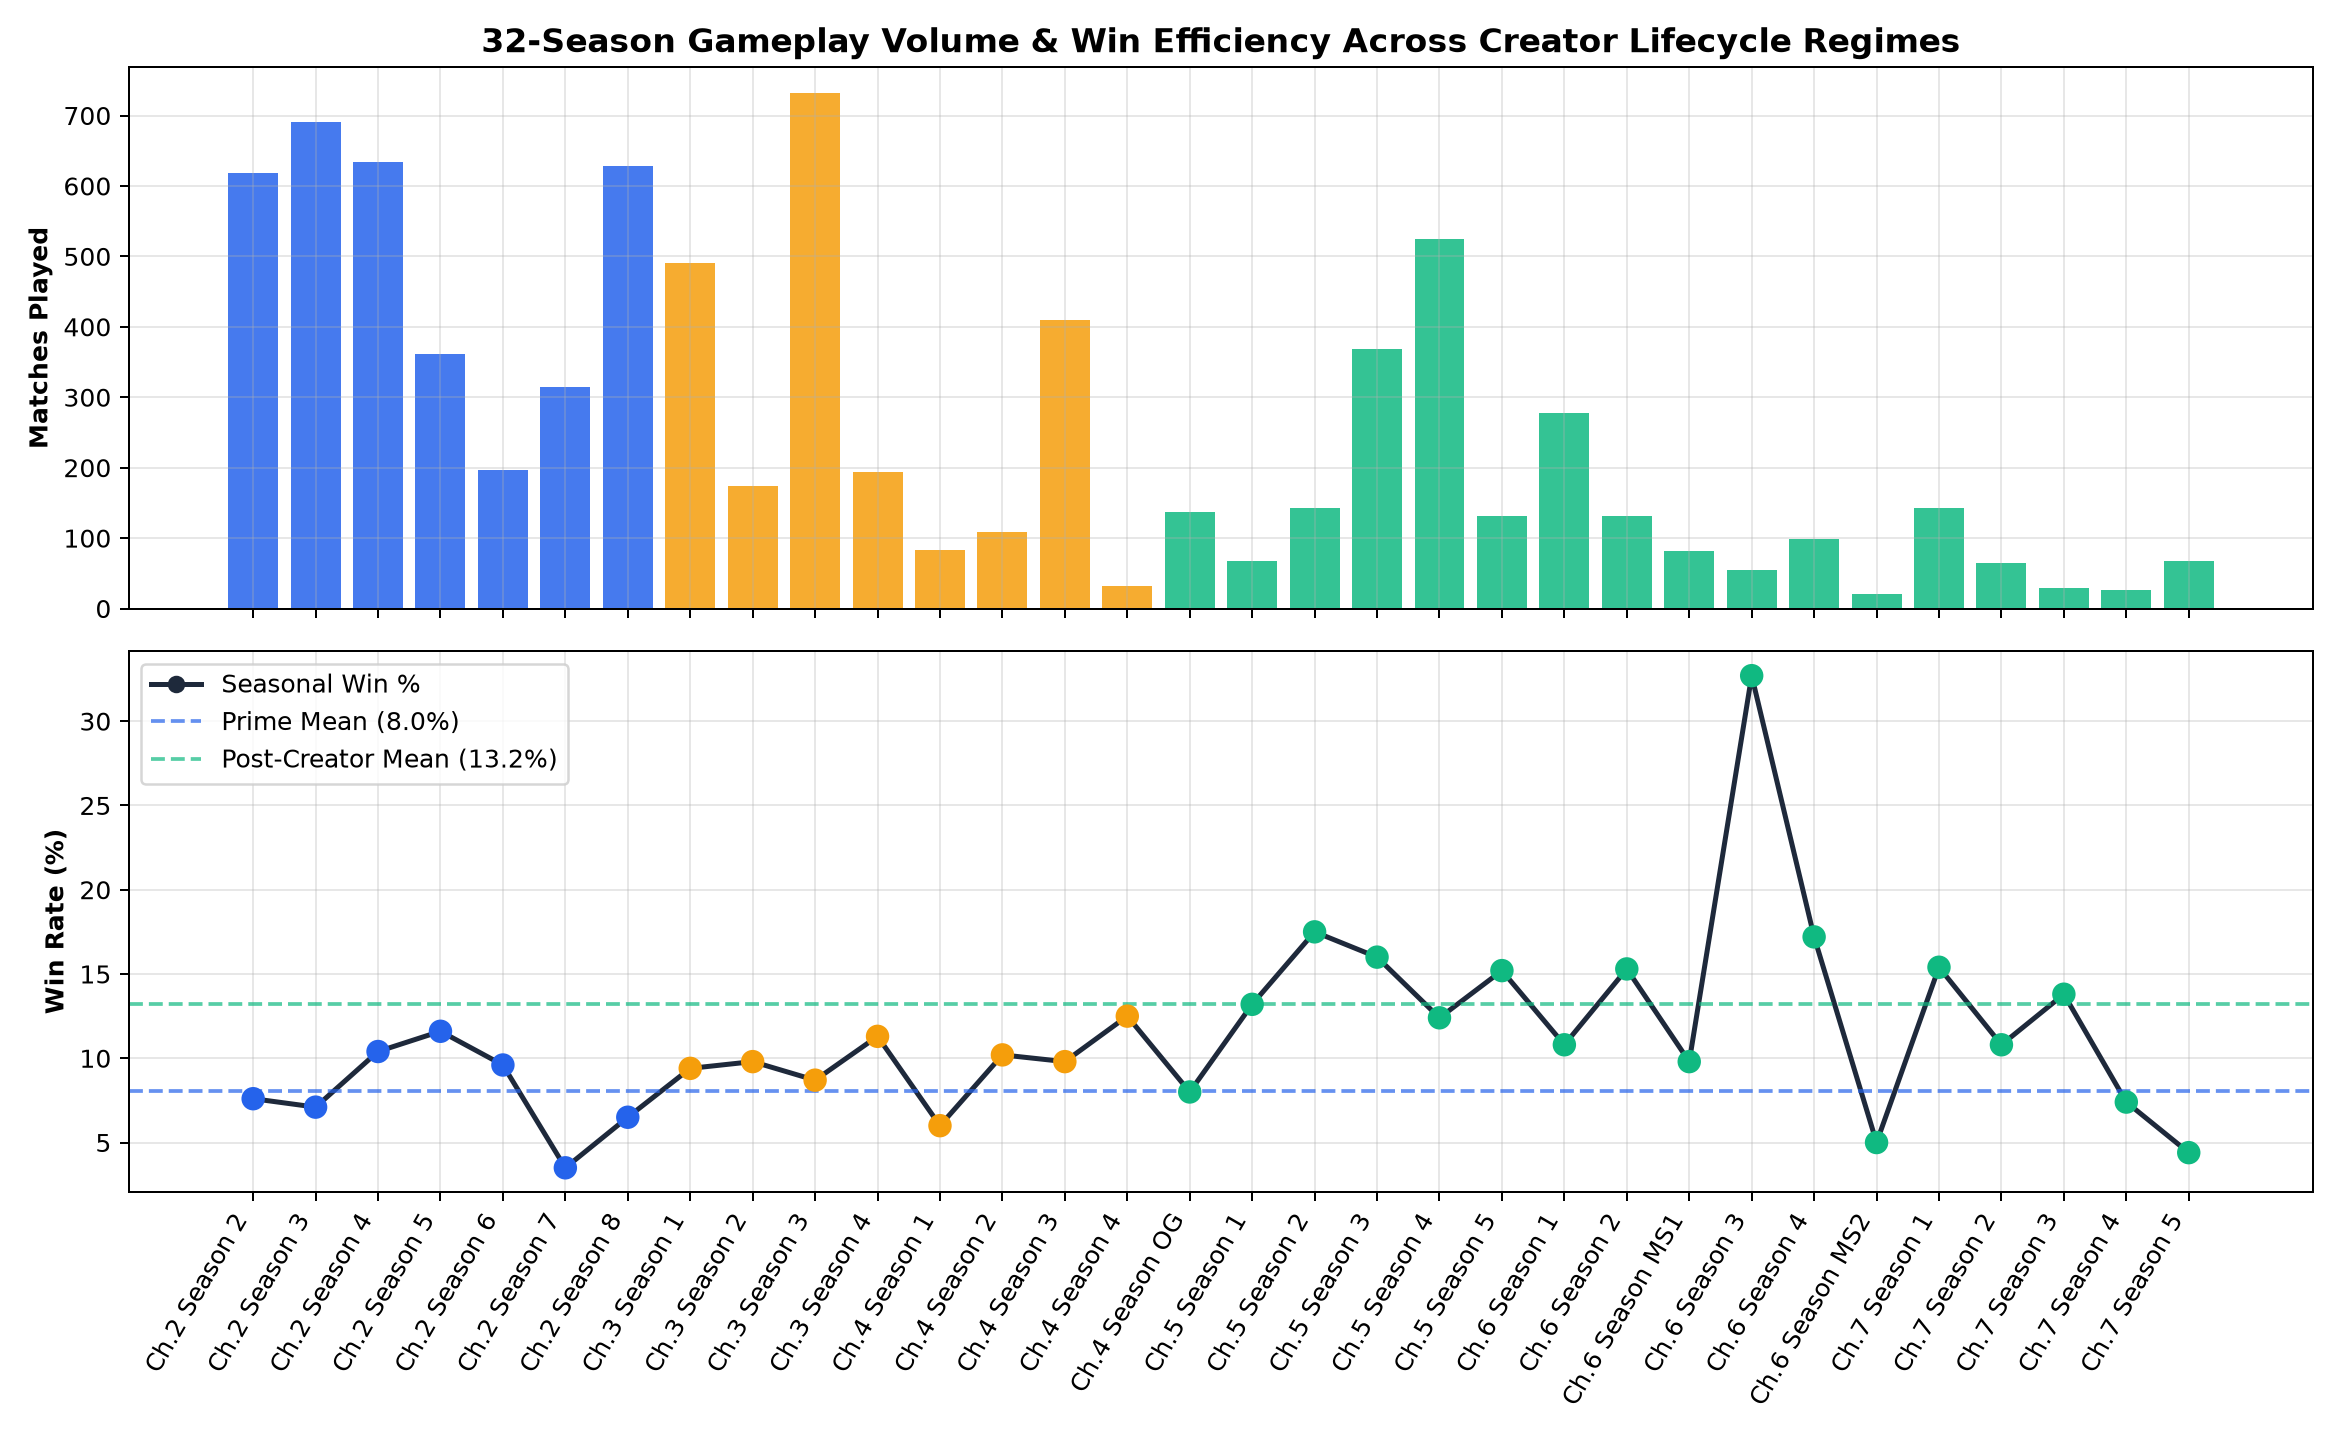

In [3]:
# 2. Hypothesis 1: Creator Burden (Fortnite Performance by Era)
prime_win = fn[fn["era"] == "Prime_Creator_Era"]["win_pct"]
decay_win = fn[fn["era"] == "Channel_Decay_Era"]["win_pct"]
post_win = fn[fn["era"] == "Post_Creator_Era"]["win_pct"]

u_prime_post, p_prime_post = stats.mannwhitneyu(prime_win, post_win, alternative="two-sided")
kw_stat, kw_p = stats.kruskal(prime_win, decay_win, post_win)
r_vol_win, p_vol_win = stats.spearmanr(fn["matches"], fn["win_pct"])

print("=== HYPOTHESIS 1: CREATOR BURDEN ===")
print(f"Kruskal-Wallis across 3 Eras (Win %): H={kw_stat:.3f}, p={kw_p:.4f}")
print(f"Mann-Whitney U (Prime vs Post-Creator Win %): U={u_prime_post:.1f}, p={p_prime_post:.4f}")
print(f"Spearman Corr (Matches Played vs Win %): r={r_vol_win:.3f}, p={p_vol_win:.4f}")

fig = Figure(figsize=(13, 8))
ax1, ax2 = fig.subplots(2, 1, sharex=True)
palette = {"Prime_Creator_Era": "#2563eb", "Channel_Decay_Era": "#f59e0b", "Post_Creator_Era": "#10b981"}
colors = fn["era"].map(palette)
ax1.bar(fn["season"], fn["matches"], color=colors, alpha=0.85)
ax1.set_ylabel("Matches Played", fontweight="bold")
ax1.set_title("32-Season Gameplay Volume & Win Efficiency Across Creator Lifecycle Regimes", fontsize=13, fontweight="bold")
ax1.grid(True, alpha=0.3)

ax2.plot(fn["season"], fn["win_pct"], color="#1e293b", marker="o", linewidth=2, label="Seasonal Win %")
ax2.scatter(fn["season"], fn["win_pct"], color=colors, s=70, zorder=5)
ax2.axhline(prime_win.mean(), color="#2563eb", linestyle="--", alpha=0.7, label=f"Prime Mean ({prime_win.mean():.1f}%)")
ax2.axhline(post_win.mean(), color="#10b981", linestyle="--", alpha=0.7, label=f"Post-Creator Mean ({post_win.mean():.1f}%)")
ax2.set_ylabel("Win Rate (%)", fontweight="bold")
ax2.legend(loc="upper left")
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis="x", rotation=60)
for label in ax2.get_xticklabels():
    label.set_ha("right")
save_and_show(fig, "01_creator_burden_seasons.png")

=== HYPOTHESIS 2: ALGORITHMIC BURNOUT ===
Monthly Uploads vs Views (Same Month): r=0.916, p=0.0000
Monthly Uploads (t-1) vs Views (t): r=0.739, p=0.0000
Detected Upload Cadence Structural Break: 2020-12 (Mann-Whitney p=0.0001)


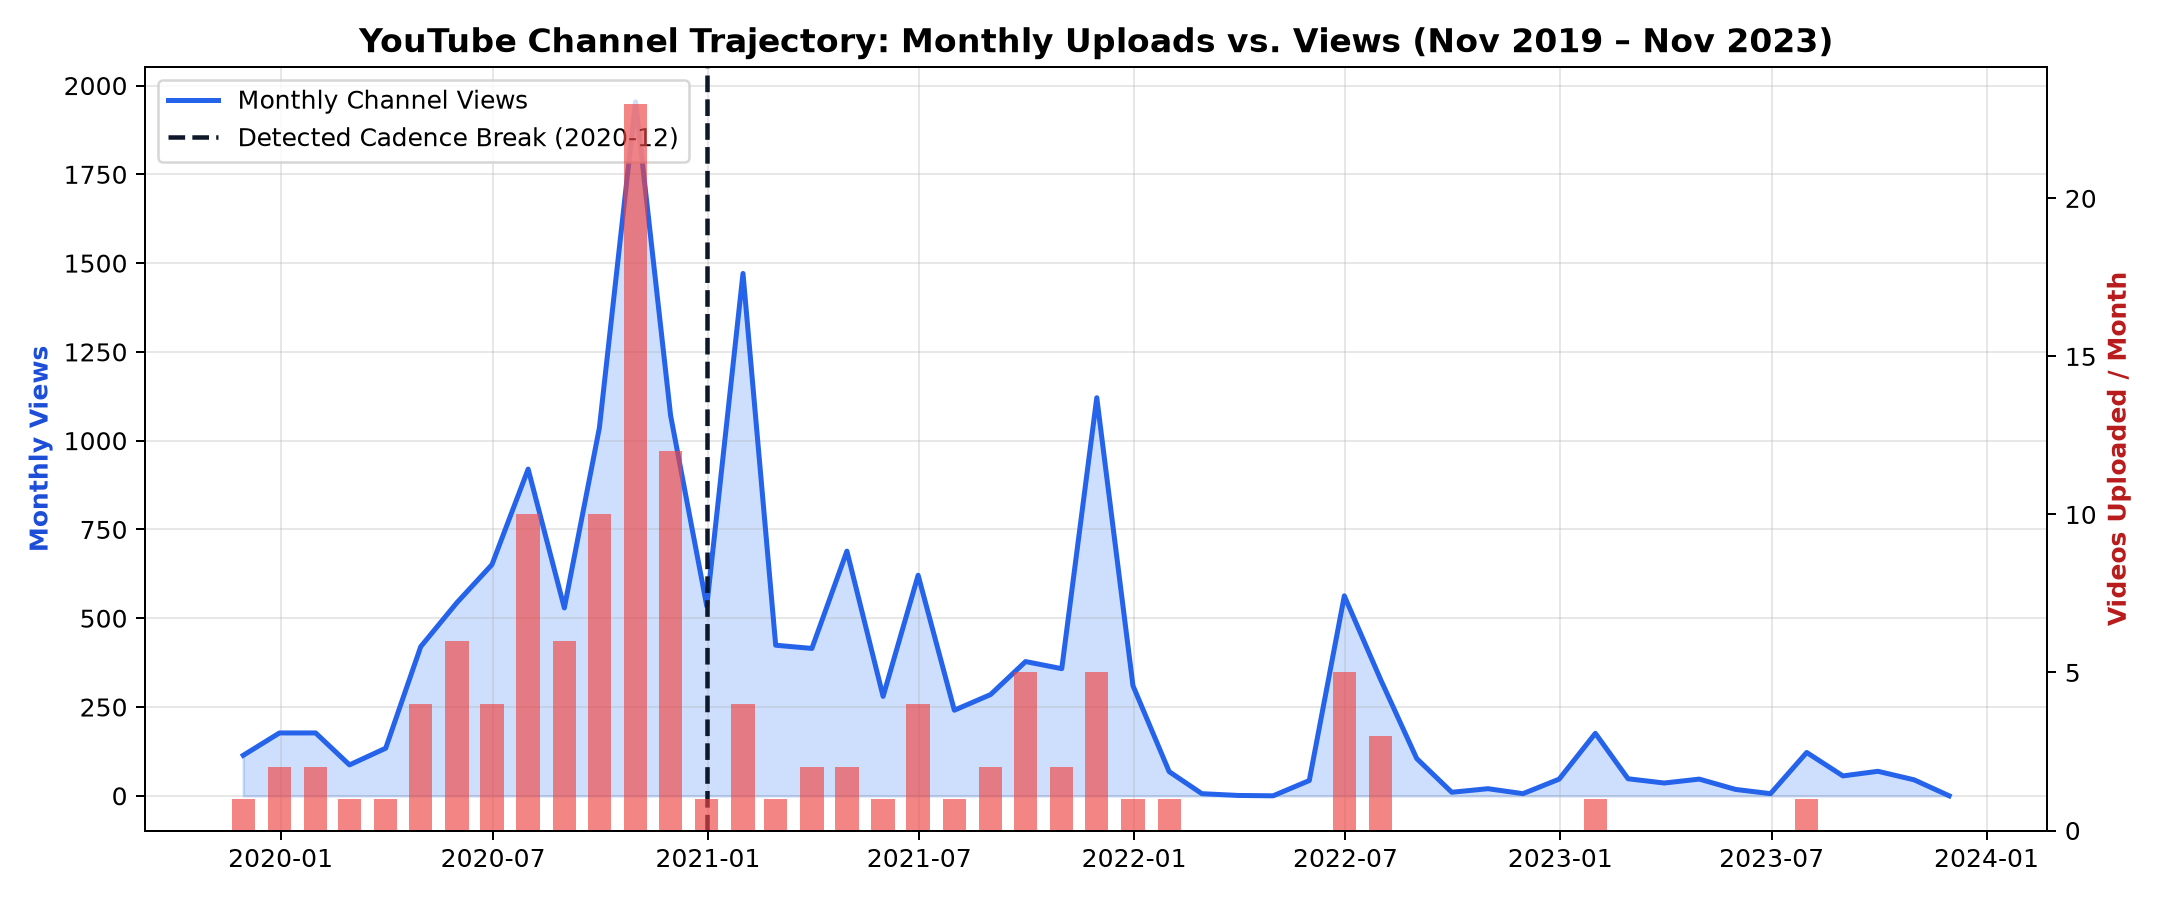

In [4]:
# 3. Hypothesis 2: Algorithmic Burnout & Change-Point Detection
monthly_views = yt_daily.set_index("Date")["Views"].resample("ME").sum()
monthly_uploads = yt_videos.set_index("publish_dt")["Content"].resample("ME").count().reindex(monthly_views.index, fill_value=0)
yt_monthly = pd.DataFrame({"views": monthly_views, "uploads": monthly_uploads})

r_same, p_same = stats.spearmanr(yt_monthly["uploads"], yt_monthly["views"])
r_lag1, p_lag1 = stats.spearmanr(yt_monthly["uploads"].shift(1).dropna(), yt_monthly["views"].iloc[1:])
bkp_idx, bkp_p = detect_single_changepoint(yt_monthly["uploads"].values)
bkp_date = yt_monthly.index[bkp_idx]

print("=== HYPOTHESIS 2: ALGORITHMIC BURNOUT ===")
print(f"Monthly Uploads vs Views (Same Month): r={r_same:.3f}, p={p_same:.4f}")
print(f"Monthly Uploads (t-1) vs Views (t): r={r_lag1:.3f}, p={p_lag1:.4f}")
print(f"Detected Upload Cadence Structural Break: {bkp_date.strftime('%Y-%m')} (Mann-Whitney p={bkp_p:.4f})")

fig = Figure(figsize=(12, 5))
ax1 = fig.subplots()
ax1.fill_between(yt_monthly.index, yt_monthly["views"], color="#3b82f6", alpha=0.25)
ax1.plot(yt_monthly.index, yt_monthly["views"], color="#2563eb", linewidth=2, label="Monthly Channel Views")
ax1.set_ylabel("Monthly Views", color="#1d4ed8", fontweight="bold")
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.bar(yt_monthly.index, yt_monthly["uploads"], width=20, color="#ef4444", alpha=0.65, label="Videos Uploaded")
ax2.set_ylabel("Videos Uploaded / Month", color="#b91c1c", fontweight="bold")
ax1.axvline(bkp_date, color="#0f172a", linestyle="--", linewidth=1.8, label=f"Detected Cadence Break ({bkp_date.strftime('%Y-%m')})")
ax1.legend(loc="upper left")
ax1.set_title("YouTube Channel Trajectory: Monthly Uploads vs. Views (Nov 2019 – Nov 2023)", fontsize=13, fontweight="bold")
save_and_show(fig, "02_youtube_burnout_timeline.png")

=== HYPOTHESIS 3: FORMAT & CLIP SESSION PATTERNS ===
                   Views                Watch time (hours)                \
                   count median    mean              count median   mean   
format                                                                     
Casual / Other        95   83.0  107.48                 95   2.99   3.47   
Edited Highlights     24  140.0  176.58                 24   2.69   3.12   
Long-Form / League     5  106.0  251.60                  5  11.18  23.06   

                   Thumbnail click-through rate (%)               
                                              count median  mean  
format                                                            
Casual / Other                                   95   8.68  8.60  
Edited Highlights                                24   9.36  9.86  
Long-Form / League                                5   6.02  7.20  


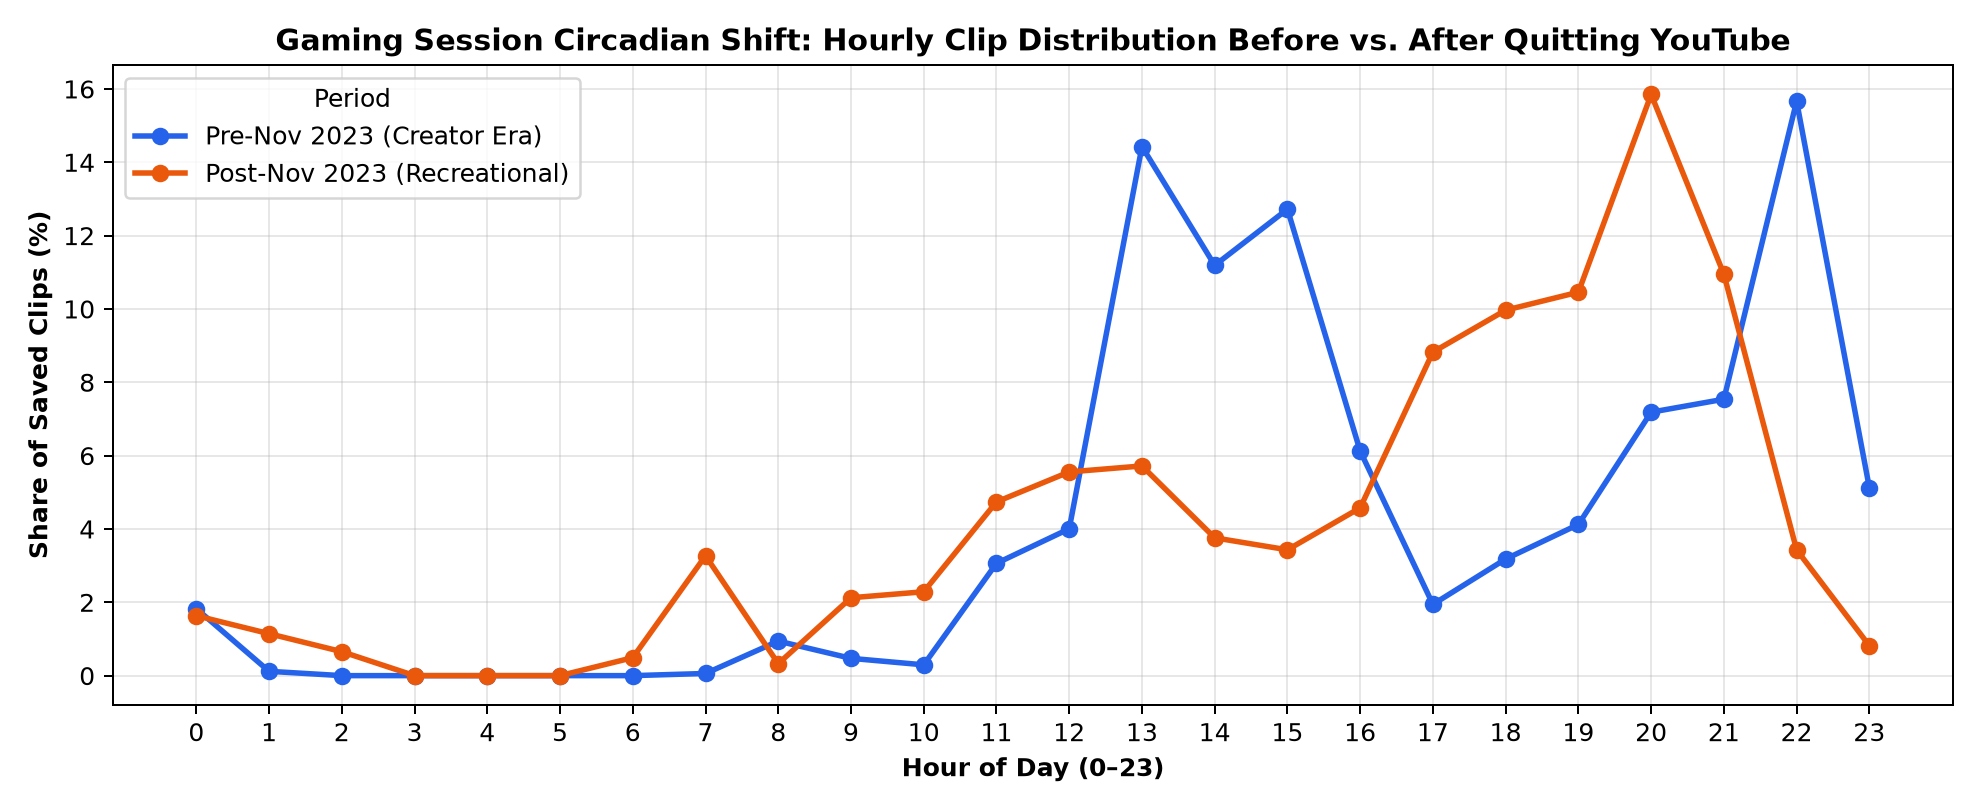

In [5]:
# 4. Hypothesis 3: Video Content Formats & Circadian Session Shift
def classify_video(title: str) -> str:
    t = str(title).lower()
    if "highlight" in t or "montage" in t or "synced" in t:
        return "Edited Highlights"
    if "revert" in t or "day " in t or "live" in t:
        return "Long-Form / League"
    return "Casual / Other"

yt_videos["format"] = yt_videos["Video title"].apply(classify_video)
print("=== HYPOTHESIS 3: FORMAT & CLIP SESSION PATTERNS ===")
print(yt_videos.groupby("format")[["Views", "Watch time (hours)", "Thumbnail click-through rate (%)"]].agg(["count", "median", "mean"]).round(2))

playable_clips["post_yt"] = playable_clips["timestamp"] >= pd.Timestamp("2023-11-02")
hourly = playable_clips.groupby(["post_yt", "hour"]).size().unstack(level=0, fill_value=0).reindex(range(24), fill_value=0)
hourly_pct = hourly.div(hourly.sum(axis=0), axis=1) * 100

fig = Figure(figsize=(11, 4.5))
ax = fig.subplots()
ax.plot(hourly_pct.index, hourly_pct[False], color="#2563eb", marker="o", linewidth=2.2, label="Pre-Nov 2023 (Creator Era)")
ax.plot(hourly_pct.index, hourly_pct[True], color="#ea580c", marker="o", linewidth=2.2, label="Post-Nov 2023 (Recreational)")
ax.set_xticks(range(0, 24))
ax.set_xlabel("Hour of Day (0–23)", fontweight="bold")
ax.set_ylabel("Share of Saved Clips (%)", fontweight="bold")
ax.set_title("Gaming Session Circadian Shift: Hourly Clip Distribution Before vs. After Quitting YouTube", fontsize=12, fontweight="bold")
ax.legend(title="Period")
ax.grid(True, alpha=0.3)
save_and_show(fig, "03_clip_circadian_shift.png")